In [30]:
from langchain_nvidia_ai_endpoints import ChatNVIDIA, NVIDIAEmbeddings
from langchain_google_genai import ChatGoogleGenerativeAI, GoogleGenerativeAIEmbeddings
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Annotated
from langchain_core.messages import BaseMessage, HumanMessage
from langgraph.graph.message import add_messages
from dotenv import load_dotenv

from langgraph.prebuilt import ToolNode, tools_condition
from langchain_tavily import TavilySearch
from langchain_core.tools import tool

import requests
import math
import os
import pypdf
from langchain_core.documents import Document
from langchain_text_splitters import RecursiveCharacterTextSplitter


In [31]:
load_dotenv()

True

In [3]:
llm = ChatNVIDIA(
    model="nvidia/nemotron-3.5-super-vl-120b-a12b",
    temperature=0,
)

In [6]:
def load_pdf_modern(file_path: str):
    reader = pypdf.PdfReader(file_path)
    documents = []
    for page_num, page in enumerate(reader.pages):
        text = page.extract_text()
        if text.strip():
            # Wrap raw text straight into LangChain's core stable Document object
            documents.append(Document(page_content=text, metadata={"page": page_num}))
    return documents

### Load Documents

In [ ]:
raw_docs = load_pdf_modern("research_paper_creatine.pdf")
len(raw_docs)

### Text Splitter

In [11]:
splitter = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=200)
chunks = splitter.split_documents(raw_docs)
# for chunk in chunks:
#     print(chunk)
#     print("==============================")

In [9]:
len(chunks)

100

### Generate Embeddings

In [ ]:
# from langchain_chroma import Chroma
# import chromadb
from langchain_community.vectorstores import FAISS 

# 1. Initialize the modern NVIDIA Embedding Model
embeddings_model = NVIDIAEmbeddings(
    model="nvidia/nemotron-3.5-embed-1b",
    truncate="END"
)

vector_store = FAISS.from_documents(chunks, embeddings_model)
vector_store.save_local("faiss_index")

In [37]:
vector_store

In [38]:
retriever = vector_store.as_retriever(search_type="similarity", search_kwargs={"k": 4})

In [41]:
ans = retriever.invoke("What is the paper about")
ans

[Document(id='ace8e85b-3d23-469a-b987-5ba8a739a656', metadata={'page': 4}, page_content='Table of contents\nAbstract................................................................................................................................................... 1\nSummary................................................................................................................................................. 3\n1. Introduction.............................................................................................................................. 6\n1.1. Background and Terms of Reference as provided by the requestor ................................................ 6\n1.2. Interpretation of the T erms of Reference ..................................................................................... 6\n1.3. Additional information ................................................................................................................ 6'),
 Document(id='416405a5-736e-48

In [43]:
@tool
def rag_tool(query: str) -> str:
    """
    Retrieve relevant information from the PDF document.

    Use this tool when the user asks factual or conceptual questions that may
    be answered by a PDF document. 

    Args:
        query: The question or search query used to retrieve information from the PDF document.
    """

    documents = retriever.invoke(query)

    if not documents:
        return "No relevant information found."

    formatted_documents = []

    for index, document in enumerate(documents, start=1):
        source = document.metadata.get("source", "Unknown source")
        page = document.metadata.get("page", "Unknown page")

        formatted_documents.append(
            f"Document {index}\n"
            f"Source: {source}\n"
            f"Page: {page}\n"
            f"Content: {document.page_content}\n"
        )

    return "\n\n".join(formatted_documents)

In [44]:
tools = [rag_tool]
llm_with_tools = llm.bind_tools(tools)

In [45]:
class ChatState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]

In [46]:
# graph nodes
def chat_node(state: ChatState):
    """LLM node that may answer or request a tool call."""
    messages = state['messages']
    response = llm_with_tools.invoke(messages)
    return {'messages': [response]}

tool_node = ToolNode(tools) # Execute tool calls

In [47]:
# graph structure
graph = StateGraph(ChatState)
graph.add_node('chat_node', chat_node)
graph.add_node('tools', tool_node)

graph.add_edge(START, 'chat_node')

# If the LLM asked for a tool, go to ToolNode; else finish
graph.add_conditional_edges('chat_node', tools_condition)

graph.add_edge('tools', 'chat_node')

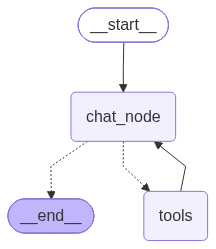

In [48]:
chatbot = graph.compile()

chatbot

In [23]:
# Regular chat
out = chatbot.invoke({"messages": [HumanMessage(content="Hello!")]})

print(out["messages"][-1].content)

Hello! How can I help you today?


In [49]:
out = chatbot.invoke({"messages": [HumanMessage(content="Using the pdf notes, explain about the effects of creatine on the body.")]})
print(out["messages"][-1].content)

Based on the PDF notes provided, here is an explanation of the effects of creatine on the body:

## What is Creatine?

Creatine is a **non-essential nitrogenous organic acid** that occurs naturally in vertebrates. In the human body, it is synthesized from three amino acids: **L-arginine, glycine, and L-methionine**. Approximately **95% of the body's creatine pool is located in skeletal muscle**, making it a key compound for muscle function.

## Primary Mechanism: ATP Regeneration

The main effect of creatine relates to energy metabolism in muscle cells:

- When creatine is ingested (at doses such as 3 g/day), it increases the **intramyocellular content of the creatine phosphate (CrP) pool**.
- This enhanced CrP pool can **improve the rate at which ATP (adenosine triphosphate) is regenerated** after intense muscle contractions.
- Since ATP is the primary energy currency for muscle contraction, having more readily available creatine phosphate allows muscles to replenish energy faster dur